# LAB 08 — Pretrained Transformers and BERT Fine-Tuning

Các Bài 13–24 dùng chung `pretrained_classification.py`. Mỗi run khởi tạo model độc lập; chỉ checkpoint validation macro-F1 tốt nhất được dùng để đánh giá. Các kết quả quick là pilot, không phải full experiment. Interpretation chỉ có `TODO(student)` theo W8.pdf.

Trên Colab: clone repo, cài requirements, chọn GPU T4, rồi chạy từ trên xuống. README có lệnh đầy đủ.

## Môi trường và imports

In [1]:
from pathlib import Path
import sys
import json
import gc
import pandas as pd
import torch
from IPython.display import display, Image

candidates = []
for parent in [Path.cwd(), *Path.cwd().parents]:
    candidates.extend([parent, parent / "Lab8", parent / "NLP" / "Lab8", parent / "lab08"])
LAB_DIR = next((p.resolve() for p in candidates
                if (p / "pretrained_classification.py").is_file()), None)
if LAB_DIR is None:
    raise FileNotFoundError("Hãy clone/upload repo NLP rồi mở notebook trong Lab8; xem README.md.")
sys.path.insert(0, str(LAB_DIR))
from pretrained_classification import (
    Config, LabRunner, build_model, count_parameters, environment_info,
    infer_texts, load_tokenizer, set_seed,
)
display(pd.Series(environment_info(), name="Environment").to_frame())
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(4)
set_seed(42)
print("Device:", DEVICE)


/home/nguyenducthang/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,Environment
python,3.12.3
torch,2.12.1+cpu
transformers,5.8.1
datasets,4.8.4
accelerate,1.13.0
scikit-learn,1.8.0
numpy,2.3.5
pandas,3.0.1
matplotlib,3.10.9
nbformat,5.11.1


Device: cpu


## Configuration và dữ liệu

Cấu hình dưới là quick pilot được đo trên CPU của lượt triển khai: 400/200/200, 2 epochs. Để chạy full, thay bằng `Config(mode="full", output_dir=str(LAB_DIR))`. Quick mặc định của CLI là 2.000/500/500, 2 epochs. Không trình bày các chế độ này như tương đương.

In [2]:
import os

config = Config(
    mode="quick", train_size=400, validation_size=200, test_size=200,
    epochs=2, batch_size=8, gradient_accumulation_steps=1, max_length=128,
    cpu_threads=4, scratch_data_curve=True,
    local_files_only=os.environ.get("HF_HUB_OFFLINE") == "1",
    output_dir=str(LAB_DIR),
)
# chỉ dùng cache khi chủ động bật HF_HUB_OFFLINE=1; Colab mặc định tự tải.
from dataclasses import asdict
display(pd.Series(asdict(config), name="Config").to_frame())
runner = LabRunner(config)
DEVICE = runner.device
display(pd.read_csv(runner.output / "split_summary.csv"))
display(pd.read_csv(runner.output / "duplicate_text_audit.csv"))
print("Labels: 0=Negative, 1=Positive")
print("source_id không overlap; exact duplicate text được audit riêng, không tự xóa dữ liệu.")


,Config
mode,quick
model_name,distilbert/distilbert-base-uncased
revision,main
seed,42
validation_fraction,0.2
train_size,400
validation_size,200
test_size,200
batch_size,8
gradient_accumulation_steps,1


Using the latest cached version of the dataset since imdb couldn't be found on the Hugging Face Hub (offline mode is enabled).


2026-11-06 01:10:43,897 WARNING Using the latest cached version of the dataset since imdb couldn't be found on the Hugging Face Hub (offline mode is enabled).


Found the latest cached dataset configuration 'plain_text' at /home/nguyenducthang/.cache/huggingface/datasets/imdb/plain_text/0.0.0/e6281661ce1c48d982bc483cf8a173c1bbeb5d31 (last modified on Sat Oct 17 10:34:20 2026).


2026-11-06 01:10:43,899 WARNING Found the latest cached dataset configuration 'plain_text' at /home/nguyenducthang/.cache/huggingface/datasets/imdb/plain_text/0.0.0/e6281661ce1c48d982bc483cf8a173c1bbeb5d31 (last modified on Sat Oct 17 10:34:20 2026).


,split,samples,negative,positive,duplicate_extra_rows
0,train,400,200,200,0
1,validation,200,100,100,0
2,test,200,100,100,0


,split_a,split_b,shared_exact_texts
0,train,validation,0
1,train,test,0
2,validation,test,0


Labels: 0=Negative, 1=Positive
source_id không overlap; exact duplicate text được audit riêng, không tự xóa dữ liệu.


## Bài 13 — Classification head và contextual representation

`AutoModelForSequenceClassification` chọn head theo architecture. Base checkpoint chưa được train sentiment: task head mới khởi tạo ngẫu nhiên, nên phần inference này chỉ kiểm tra API. Đánh giá sentiment thật dùng checkpoint đã fine-tune ở Bài 19.

In [3]:
core_model = build_model(config, "pretrained", "fine_tuning").to(DEVICE)
print("Architecture:", type(core_model).__name__)
print("Encoder:", core_model.base_model_prefix)
for name, module in core_model.named_children():
    if name != core_model.base_model_prefix:
        print("Head component:", name, module)
print(count_parameters(core_model))
single, hidden = infer_texts(core_model, runner.tokenizer, ["I enjoyed this movie."], DEVICE)
display(single)
print("Contextual representation:", tuple(hidden.shape))
batch_predictions, hidden_batch = infer_texts(core_model, runner.tokenizer,
    ["I enjoyed this movie.", "The ending was disappointing."], DEVICE)
display(batch_predictions)
print("Batch contextual representation:", tuple(hidden_batch.shape))
del core_model, hidden, hidden_batch
gc.collect()
if torch.cuda.is_available(): torch.cuda.empty_cache()


2026-11-06 01:10:44,286 WARNING Failed to load /home/nguyenducthang/.venv/lib/python3.12/site-packages/torchao/_C_mxfp8.cpython-310-x86_64-linux-gnu.so: Could not load this library: /home/nguyenducthang/.venv/lib/python3.12/site-packages/torchao/_C_mxfp8.cpython-310-x86_64-linux-gnu.so


2026-11-06 01:10:44,287 WARNING Failed to load /home/nguyenducthang/.venv/lib/python3.12/site-packages/torchao/_C_cutlass_90a.abi3.so: Could not load this library: /home/nguyenducthang/.venv/lib/python3.12/site-packages/torchao/_C_cutlass_90a.abi3.so


W1106 01:10:44.496000 120360 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


W1106 01:10:44.518000 120360 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.



Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 100/100 [00:00<00:00, 2598.04it/s]

... (2 outputs left out)

,text,logits,p_negative,p_positive,prediction
0,I enjoyed this movie.,"[0.0007456280291080475, -0.04518928378820419]",0.511482,0.488518,Negative


Contextual representation: (1, 7, 768)


,text,logits,p_negative,p_positive,prediction
0,I enjoyed this movie.,"[0.0007456284947693348, -0.0451892651617527]",0.511482,0.488518,Negative
1,The ending was disappointing.,"[0.004417949356138706, -0.03445745259523392]",0.509718,0.490282,Negative


Batch contextual representation: (2, 7, 768)


## Bài 14 — Experiment 1: Pretrained vs From Scratch

Giữ architecture, tokenizer, split, data size, epoch budget, learning rate và maximum length. From scratch gọi `from_config`; pretrained gọi `from_pretrained`. Bảng so sánh dưới dùng **validation**, không đổi nhãn thành test.

In [4]:
comparison_initialization = runner.pretrained_vs_scratch()
display(comparison_initialization[["initialization", "split", "train_samples", "accuracy", "f1_macro",
    "training_time_seconds", "total_parameters", "trainable_parameters"]])

2026-11-06 01:10:44,880 INFO reuse completed run quick-scratch-fine_tuning-f1-l128-7ac1e0072268


2026-11-06 01:10:44,891 INFO reuse completed run quick-pretrained-fine_tuning-f1-l128-b106a95c8b3e


,initialization,split,train_samples,accuracy,f1_macro,training_time_seconds,total_parameters,trainable_parameters
0,scratch,validation,400,0.500,0.333333,158.361923,66955010,66955010
1,pretrained,validation,400,0.795,0.794749,165.120459,66955010,66955010


`TODO(student)`: representation, lượng training data cần thiết và chi phí tính toán khác nhau ra sao? Kết quả có khớp prediction không? Một learning rate/budget chung có thể chưa tối ưu riêng cho mỗi initialization; không suy luận từ pilot thành kết luận tổng quát.

## Bài 15 — Experiment 2: Frozen vs Fine-tuning

Hai run đều bắt đầu từ cùng pretrained checkpoint. Frozen encoder có `requires_grad=False` và giữ eval mode trong huấn luyện; toàn bộ head vẫn trainable. Full fine-tuning cho encoder cập nhật.

In [5]:
comparison_freezing = runner.frozen_vs_finetuning()
display(comparison_freezing[["train_mode", "encoder_trainable", "accuracy", "f1_macro", "training_time_seconds", "trainable_parameters"]])
print("Encoder trainable:", {"frozen":False, "fine_tuning":True}, "(asserted in build_model)")

2026-11-06 01:10:44,915 INFO reuse completed run quick-pretrained-frozen-f1-l128-15b35f73e542


2026-11-06 01:10:44,924 INFO reuse completed run quick-pretrained-fine_tuning-f1-l128-b106a95c8b3e


,train_mode,encoder_trainable,accuracy,f1_macro,training_time_seconds,trainable_parameters
0,frozen,False,0.640,0.592944,40.525656,592130
1,fine_tuning,True,0.795,0.794749,165.120459,66955010


Encoder trainable: {'frozen': False, 'fine_tuning': True} (asserted in build_model)


`TODO(student)`: vì sao frozen vẫn phân loại được? Kết quả fine-tuning có cải thiện không, và evidence là gì?

## Bài 16 — Experiment 3: Amount of Training Data

Các tập con 10%, 25%, 50%, 100% là nested và stratified; validation/test giữ cố định. Mỗi tỷ lệ khởi tạo lại từ pretrained hoặc random weights theo cấu hình, không tiếp tục train từ tỷ lệ trước.

2026-11-06 01:10:44,946 INFO reuse completed run quick-pretrained-fine_tuning-f0.1-l128-f17f7aaf3f7b


2026-11-06 01:10:44,956 INFO reuse completed run quick-pretrained-fine_tuning-f0.25-l128-ebbd2f1d94a0


2026-11-06 01:10:44,970 INFO reuse completed run quick-pretrained-fine_tuning-f0.5-l128-06487fa8a5e4


2026-11-06 01:10:44,979 INFO reuse completed run quick-pretrained-fine_tuning-f1-l128-b106a95c8b3e


2026-11-06 01:10:44,988 INFO reuse completed run quick-scratch-fine_tuning-f0.1-l128-38aef12c5a46


2026-11-06 01:10:44,996 INFO reuse completed run quick-scratch-fine_tuning-f0.25-l128-771c008a0c4a


2026-11-06 01:10:45,005 INFO reuse completed run quick-scratch-fine_tuning-f0.5-l128-f78f0859f74b


2026-11-06 01:10:45,015 INFO reuse completed run quick-scratch-fine_tuning-f1-l128-7ac1e0072268


,initialization,train_fraction,train_samples,split,accuracy,f1_macro,training_time_seconds
0,pretrained,0.10,40,validation,0.550,0.539642,17.740395
1,pretrained,0.25,100,validation,0.640,0.636364,49.855834
2,pretrained,0.50,200,validation,0.680,0.671593,91.956406
3,pretrained,1.00,400,validation,0.795,0.794749,165.120459
4,scratch,0.10,40,validation,0.500,0.333333,15.787768
5,scratch,0.25,100,validation,0.500,0.333333,35.554611
6,scratch,0.50,200,validation,0.500,0.333333,74.063163
7,scratch,1.00,400,validation,0.500,0.333333,158.361923


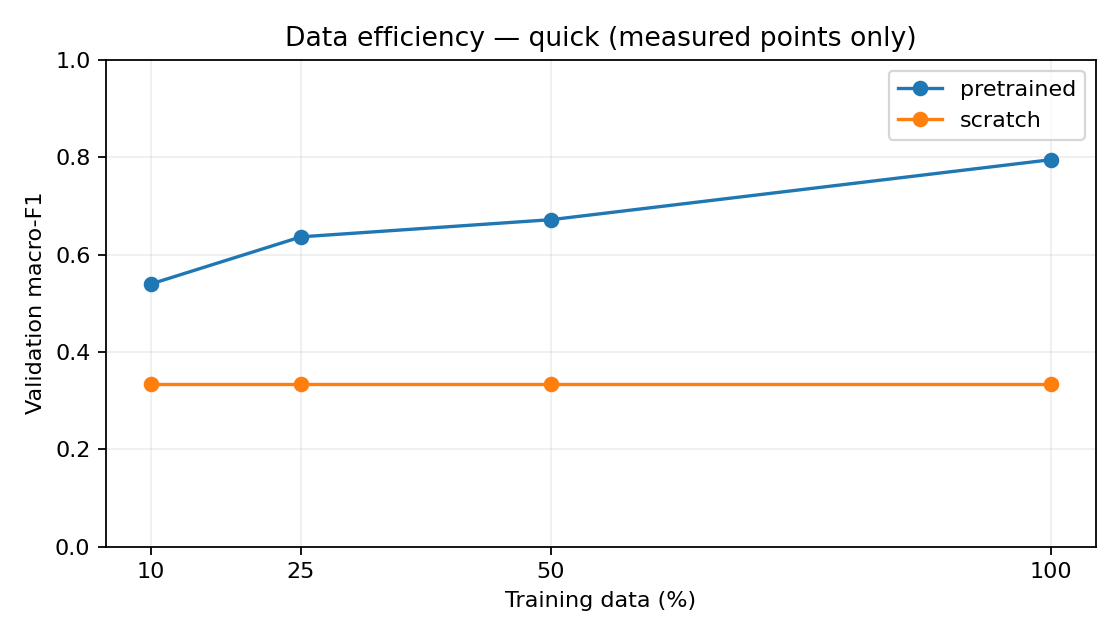

In [6]:
data_results = runner.data_efficiency()
display(data_results[["initialization", "train_fraction", "train_samples", "split", "accuracy", "f1_macro", "training_time_seconds"]])
display(Image(filename=str(LAB_DIR / "data_efficiency.png")))

`TODO(student)`: đọc toàn bộ đường cong để tự nhận xét data efficiency. Nếu chỉ chạy curve pretrained, chưa đủ evidence để kết luận model nào bị ảnh hưởng mạnh hơn khi giảm dữ liệu.

## Bài 17 — Experiment 4: Maximum Sequence Length

Các run 64/128/256 giữ các tham số khác như nhau. Memory được đo bằng `max_memory_allocated` trên CUDA; CPU peak chưa đo thì để null. Bộ nhớ attention lý thuyết và thời gian đo thực tế không phải cùng đại lượng.

In [7]:
length_results = runner.sequence_length()
display(length_results[["max_length", "split", "accuracy", "f1_macro", "training_time_seconds", "peak_gpu_memory_mb"]])

2026-11-06 01:10:45,130 INFO reuse completed run quick-pretrained-fine_tuning-f1-l64-012bfb3a72b0


2026-11-06 01:10:45,140 INFO reuse completed run quick-pretrained-fine_tuning-f1-l128-b106a95c8b3e


2026-11-06 01:10:45,149 INFO reuse completed run quick-pretrained-fine_tuning-f1-l256-6ed333c9956d


,max_length,split,accuracy,f1_macro,training_time_seconds,peak_gpu_memory_mb
0,64,validation,0.725,0.722999,82.651963,None
1,128,validation,0.795,0.794749,165.120459,None
2,256,validation,0.815,0.813315,243.312557,None


`TODO(student)`: length lớn hơn có luôn cải thiện performance? So sánh mức thay đổi F1 với chi phí thực tế; không giả định thời gian toàn bộ training tỷ lệ chính xác với T².

## Bài 18 — Experiment 5: Domain Shift

IMDb movie reviews → Yelp Polarity (review nhà hàng/dịch vụ). Cả hai có 0=Negative, 1=Positive. Domain B chỉ dùng để đánh giá; không train/tune bằng nhãn của B. Delta được tính B − A.

In [8]:
try:
    domain_results = runner.domain_shift()
    display(domain_results[["domain", "split", "test_samples", "accuracy", "f1_macro",
        "accuracy_delta_b_minus_a", "f1_macro_delta_b_minus_a"]])
except (OSError, ConnectionError) as error:
    runner.status("18", "BLOCKED", str(error))
    print("BLOCKED: không tải được Domain B.", error)
    print("Có thể dùng Config(domain_b_file='domain_b.csv') với cột text và label (0/1).")

2026-11-06 01:10:45,176 INFO reuse completed run quick-pretrained-fine_tuning-f1-l128-b106a95c8b3e


Using the latest cached version of the dataset since fancyzhx/yelp_polarity couldn't be found on the Hugging Face Hub (offline mode is enabled).


2026-11-06 01:10:45,178 WARNING Using the latest cached version of the dataset since fancyzhx/yelp_polarity couldn't be found on the Hugging Face Hub (offline mode is enabled).


Found the latest cached dataset configuration 'plain_text' at /home/nguyenducthang/.cache/huggingface/datasets/fancyzhx___yelp_polarity/plain_text/0.0.0/bbf1c97a1f0cf005e5aded43839fd814654a1557 (last modified on Fri Nov  6 00:41:24 2026).


2026-11-06 01:10:45,180 WARNING Found the latest cached dataset configuration 'plain_text' at /home/nguyenducthang/.cache/huggingface/datasets/fancyzhx___yelp_polarity/plain_text/0.0.0/bbf1c97a1f0cf005e5aded43839fd814654a1557 (last modified on Fri Nov  6 00:41:24 2026).



Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 104/104 [00:00<00:00, 2452.52it/s]

,domain,split,test_samples,accuracy,f1_macro,accuracy_delta_b_minus_a,f1_macro_delta_b_minus_a
0,IMDb,test,200,0.80,0.799499,NaN,NaN
1,Yelp Polarity,test,200,0.85,0.849261,0.05,0.049763


`TODO(student)`: tự giải thích thay đổi performance bằng evidence. Chưa có Domain B thì ghi rõ chưa đủ dữ liệu để kết luận.

## Bài 19 — Application và final IMDb Test

Cấu hình tham chiếu được định trước: pretrained, fine-tuning, 100% train của mode hiện tại, max length cấu hình chính. Không chọn model bằng test F1. Checkpoint từng run chọn bằng validation macro-F1.

2026-11-06 01:11:02,327 INFO reuse completed run quick-pretrained-fine_tuning-f1-l128-b106a95c8b3e



Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 104/104 [00:00<00:00, 2645.59it/s]

,run_id,split,test_samples,accuracy,precision_macro,recall_macro,f1_macro,f1_binary
0,quick-pretrained-fine_tuning-f1-l128-b106a95c8b3e,test,200,0.8,0.80303,0.8,0.799499,0.789474


,Negative,Positive
Negative,85,15
Positive,25,75


,precision,recall,f1-score,support
Negative,0.772727,0.85,0.809524,100.0
Positive,0.833333,0.75,0.789474,100.0
macro avg,0.803030,0.80,0.799499,200.0
weighted avg,0.803030,0.80,0.799499,200.0


Test accuracy: 0.8


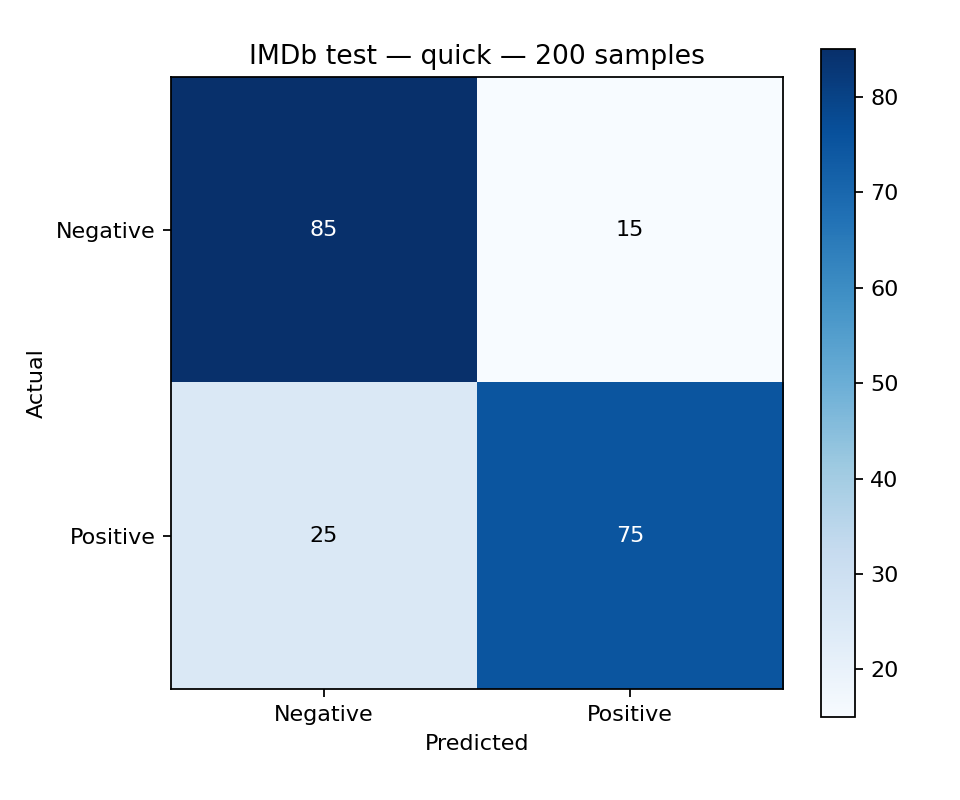

In [9]:
application_results, test_confusion_matrix, confidence_groups = runner.application()
display(application_results[["run_id", "split", "test_samples", "accuracy", "precision_macro", "recall_macro", "f1_macro", "f1_binary"]])
display(test_confusion_matrix)
report = json.loads((runner.output / "classification_report.json").read_text())
display(pd.DataFrame({k:v for k,v in report.items() if isinstance(v,dict)}).T)
print("Test accuracy:", report["accuracy"])
display(Image(filename=str(LAB_DIR / "confusion_matrix.png")))

### Inference với một review mới hoặc batch review

In [10]:
reference_run = runner.run_model("pretrained", "fine_tuning", 1.0, config.max_length)
application_model = runner.load_run(reference_run)
reviews = [
    "I loved the acting and the ending.",
    "I did not enjoy this movie.",
    "The beginning was great but the rest was disappointing.",
    "The plot was predictable. " * 50 + "Overall I disliked it.",
]
new_predictions, representations = infer_texts(application_model, runner.tokenizer, reviews, DEVICE, config.max_length)
display(new_predictions)
print("Token representation shape:", tuple(representations.shape))
del application_model, representations
gc.collect()

2026-11-06 01:11:12,727 INFO reuse completed run quick-pretrained-fine_tuning-f1-l128-b106a95c8b3e



Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 104/104 [00:00<00:00, 2843.60it/s]

,text,logits,p_negative,p_positive,prediction
0,I loved the acting and the ending.,"[-0.9589228630065918, 0.7808094024658203]",0.149347,0.850653,Positive
1,I did not enjoy this movie.,"[0.5463332533836365, -0.5413677096366882]",0.747949,0.252051,Negative
2,The beginning was great but the rest was disap...,"[0.5121397376060486, -0.6190223097801208]",0.756053,0.243947,Negative
3,The plot was predictable. The plot was predict...,"[0.5176476836204529, -0.6727787852287292]",0.766817,0.233183,Negative


Token representation shape: (4, 128, 768)


0

## Bài 20 — Error candidates (không tự gán nguyên nhân)

Mã chọn tối đa 3 FP, 3 FN và 2 high-confidence wrong nếu có. Một review có thể thỏa nhiều nhóm nhưng không bị lặp trong danh sách. `error_type` và `hypothesis` dành cho sinh viên.

In [11]:
error_candidates = pd.read_csv(runner.output / "error_candidates.csv")
display(error_candidates)
display(pd.DataFrame(json.loads((runner.output / "error_availability.json").read_text())).T)
print("TODO(student): đọc", LAB_DIR / "error_analysis.md", "và tự điền error_type/hypothesis.")

,source_id,text,true_label,predicted_label,p_negative,p_positive,confidence,correct,outcome,error_type,hypothesis
0,imdb-test-20411,"OK firstly, if your not a fan of the whole low...",1,0,0.926751,0.073249,0.926751,False,FN,TODO(student),TODO(student)
1,imdb-test-12024,Jack Lemmon was one of the finest actors that ...,0,1,0.093683,0.906317,0.906317,False,FP,TODO(student),TODO(student)
2,imdb-test-19904,I found this one to be more chaotic than the a...,1,0,0.898950,0.101050,0.898950,False,FN,TODO(student),TODO(student)
3,imdb-test-16344,This movie possesses something most other movi...,1,0,0.896973,0.103027,0.896973,False,FN,TODO(student),TODO(student)
4,imdb-test-9115,In the aftermath of September 11th in New York...,0,1,0.110808,0.889192,0.889192,False,FP,TODO(student),TODO(student)
5,imdb-test-1328,For those of you who have never heard of the m...,0,1,0.122654,0.877346,0.877346,False,FP,TODO(student),TODO(student)


,available,requested,missing
FP,15,3,0
FN,25,3,0
high_confidence_wrong,2,2,0


TODO(student): đọc /home/nguyenducthang/NLP/Lab8/error_analysis.md và tự điền error_type/hypothesis.


## Bài 21 — Confidence analysis

Confidence là giá trị lớn nhất của softmax. Các ngưỡng nằm trong config. Nhóm rỗng có accuracy/mean confidence null; không xem confidence là calibration đã được chứng minh.

High ≥ 0.9 | Medium ≥ 0.7 and < High | Low < Medium


,group,count,correct,incorrect,accuracy,mean_confidence
0,High,55,53,2,0.963636,0.914851
1,Medium,100,79,21,0.790000,0.830643
2,Low,45,28,17,0.622222,0.606328


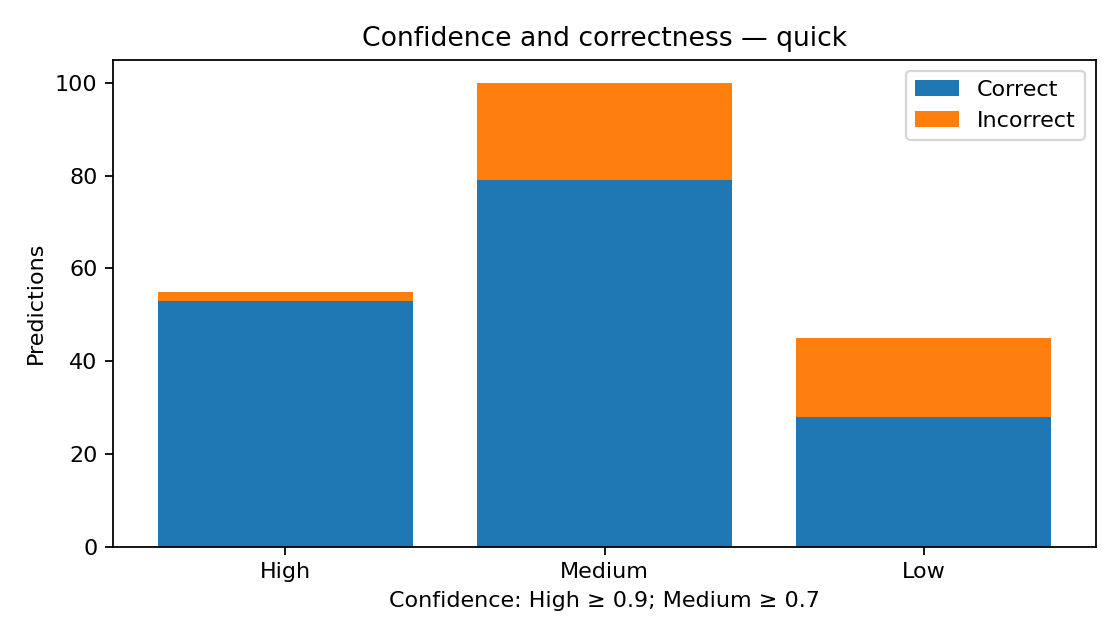

In [12]:
print("High ≥", config.high_confidence, "| Medium ≥", config.medium_confidence, "and < High | Low < Medium")
display(pd.read_csv(runner.output / "confidence_groups.csv"))
display(Image(filename=str(LAB_DIR / "confidence_analysis.png")))

`TODO(student)`: confidence cao có đồng nghĩa đúng không? Trích số lượng dự đoán đúng/sai thực tế ở mỗi nhóm; không tạo ví dụ high-confidence wrong nếu không tồn tại.

## Bài 22 — Controlled ablation

Các Bài 14–17 là các phép so sánh có kiểm soát. Cột run_mode và config_hash phân biệt điều kiện chạy; quick/smoke không thay thế full.

In [13]:
all_results = pd.read_csv(LAB_DIR / "results.csv")
display(all_results[all_results.run_mode == config.mode].groupby(["experiment_id", "split"]).size().rename("measured_rows").to_frame())

,,measured_rows
experiment_id,split,
14,validation,2
15,validation,2
16,validation,8
17,validation,3
18,test,2
19,test,1


## Bài 23 — Reproducibility và completion report

In [14]:
runner.write_completion_report()
display(pd.Series(runner.environment, name="Environment").to_frame())
display(pd.read_csv(runner.output / "status.csv"))
print("Detailed config:", runner.output / "config.json")
print("Manifests, run configs, history, checkpoints and logs:", runner.output)
print("Technical verification:", LAB_DIR / "outputs" / "verification.json")

,Environment
python,3.12.3
torch,2.12.1+cpu
transformers,5.8.1
datasets,4.8.4
accelerate,1.13.0
scikit-learn,1.8.0
numpy,2.3.5
pandas,3.0.1
matplotlib,3.10.9
nbformat,5.11.1


,experiment,status,message
0,14,EXECUTED,"same architecture/tokenizer, validation compar..."
1,15,EXECUTED,encoder requires_grad checked at model constru...
2,16,EXECUTED,all four nested fractions; scratch curve is op...
3,17,EXECUTED,CPU peak memory not measured if no CUDA
4,18,EXECUTED,A=IMDb B=Yelp Polarity; delta=B-A; nB=200
5,19,EXECUTED,test n=200; reference=quick-pretrained-fine_tu...
6,20,GENERATED,"{""FP"": {""available"": 15, ""requested"": 3, ""miss..."
7,21,GENERATED,thresholds recorded in config; empty groups ha...


Detailed config: /home/nguyenducthang/NLP/Lab8/outputs/quick/config.json
Manifests, run configs, history, checkpoints and logs: /home/nguyenducthang/NLP/Lab8/outputs/quick
Technical verification: /home/nguyenducthang/NLP/Lab8/outputs/verification.json


## Bài 24 — AI Usage

| Mục | Đóng góp kỹ thuật của Codex |
|---|---|
| AI-assisted code | Tokenization, initialization, training/evaluation, visualization, tests và notebook |
| What was generated | Pipeline so sánh, config, artifacts, các template tự làm |
| What was modified | Code LAB 08 mới; không dựa vào việc người học đã tự review |
| What was verified | Xem `outputs/verification.json`, logs và `completion_report.md` cho phần đã chạy thực tế |

## Phần người học tự hoàn thiện

- `calculations.md`: MLM, tokenization và learning check.
- `prediction.md`: prediction viết trước khi xem kết quả.
- Nhận xét các experiment: dùng evidence, tự viết interpretation.
- `error_analysis.md`: error type, hypothesis và sáu câu hỏi bắt buộc.
- `reflection.md`: bài 300–500 từ bằng lời của mình.